Бизнес-постановка задачи
Контекст. Маркетплейс ежедневно получает тысячи отзывов на товары. Служба поддержки и продавцы физически не успевают читать все отзывы, чтобы вовремя реагировать на проблемы (брак, задержки доставки, обман).

Проблема. Негативные отзывы, оставленные без ответа, снижают рейтинг продавца, отпугивают новых покупателей и приводят к возвратам и оттоку клиентов. При этом ручная сортировка отзывов не масштабируется.

Цель. Автоматически помечать отзыв как "негативный" (передать в приоритетную очередь поддержки для ответа и компенсации) или "позитивный/нейтральный" (обрабатывать стандартным образом). Это ускоряет реакцию на негатив и снижает отток клиентов.

Постановка ML-задачи
Тип задачи. Бинарная классификация текстов.

Целевая переменная. label принадлежит множеству {0, 1}, где 1 - негативный отзыв, 0 - позитивный или нейтральный.

Входные данные. Числовые и бинарные признаки, извлечённые из текста отзыва:

text - сам текст отзыва (используется для интерпретации);
length - длина отзыва в символах;
num_exclam - количество восклицательных знаков;
num_digits - количество цифр (например, номер заказа);
num_neg_words - количество негативных слов («брак», «плохо», «обман», «ужас» и т.п.);
num_pos_words - количество позитивных слов («отлично», «супер», «рекомендую»);
has_refund_request - 1, если отзыв содержит просьбу о возврате или жалобе.

Формальная постановка. Дано множество объектов X = {x1, ..., x150} и множество меток Y = {y1, ..., y150}, где каждая метка yi принадлежит множеству {0, 1}. Требуется построить решающую функцию f, отображающую X в {0, 1}, которая максимизирует выбранную метрику качества на отложенной выборке.

Источник. Синтетический датасет, сгенерированный вручную и сохранённый в файл dataset.csv (150 записей, 8 колонок).

Структура:

Колонка	Тип	Описание
text	str	Текст отзыва
length	int	Длина отзыва в символах
num_exclam	int	Кол-во восклицательных знаков
num_digits	int	Кол-во цифр
num_neg_words	int	Кол-во негативных слов
num_pos_words	int	Кол-во позитивных слов
has_refund_request	int	Просьба о возврате / жалоба
label	int	1 - негативный, 0 - позитивный/нейтральный

Дисбаланс. ~45% негатива / 55% позитива - умеренный, требует стратификации при разбиении.

Проверка после загрузки:




In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset.csv", encoding="utf-8")

print(df.shape)
print(df.info())
print(df.describe())
print(df["label"].value_counts(normalize=True))

(144, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   text                144 non-null    object
 1   length              144 non-null    int64 
 2   num_exclam          144 non-null    int64 
 3   num_digits          144 non-null    int64 
 4   num_neg_words       144 non-null    int64 
 5   num_pos_words       144 non-null    int64 
 6   has_refund_request  144 non-null    int64 
 7   label               144 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 9.1+ KB
None
           length  num_exclam  num_digits  num_neg_words  num_pos_words  \
count  144.000000  144.000000  144.000000     144.000000     144.000000   
mean    42.812500    0.555556    0.909722       1.118056       1.076389   
std      9.006578    0.791368    1.869569       1.214692       1.109904   
min     26.000000    0.000000    0.000000       0.00

Метрика качества и её обоснование (8 баллов)
Выбранные метрики: F1-мера (основная) и Recall по классу «негативный» (контрольная).

Обоснование.

Почему не Accuracy? При дисбалансе 45/55 accuracy ≈ 55% достигается тривиальным "всегда позитив", что бесполезно для бизнеса.

Почему F1, а не F2? В отличие от спама, здесь ложное срабатывание тоже дорого: если поддержка будет отвечать на каждый позитивный отзыв как на негатив, это перегрузит операторов и снизит скорость реакции на реальные проблемы. F1 балансирует Precision и Recall - это соответствует бизнес-логике «одинаково важно не пропустить негатив и не завалить поддержку лишними тикетами».

Почему дополнительно Recall? Пропуск негативного отзыва (FN) ведёт к оттоку клиента и падению рейтинга, поэтому отдельно контролируем, какую долю реального негатива модель находит. Recall по классу 1 - прямой KPI службы поддержки.

Почему PR-AUC не обязателен? Дисбаланс умеренный, классы сопоставимы - F1 + Recall достаточно информативны и легко интерпретируются бизнесом.

Получим базовые статистики:

C:\Users\densa\AppData\Local\Temp\ipykernel_21916\501135283.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="label", data=df, palette="Set2")


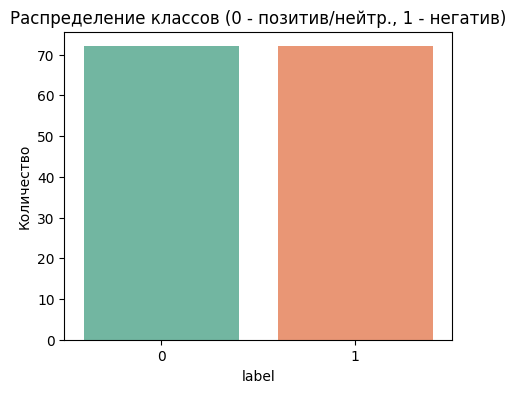

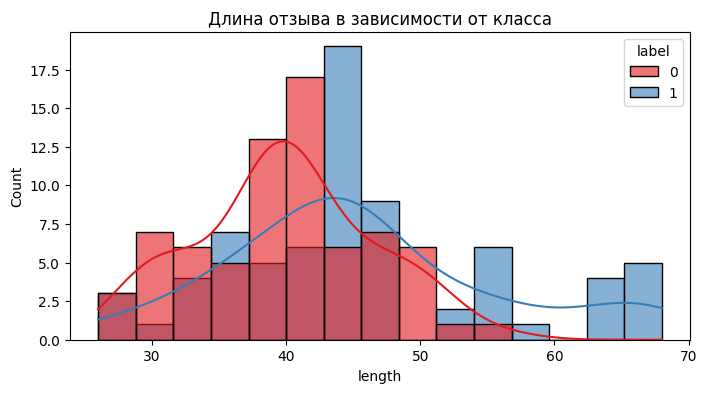

C:\Users\densa\AppData\Local\Temp\ipykernel_21916\501135283.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="label", y="num_neg_words", data=df, ax=axes[0], palette="Reds")
C:\Users\densa\AppData\Local\Temp\ipykernel_21916\501135283.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="label", y="num_pos_words", data=df, ax=axes[1], palette="Greens")


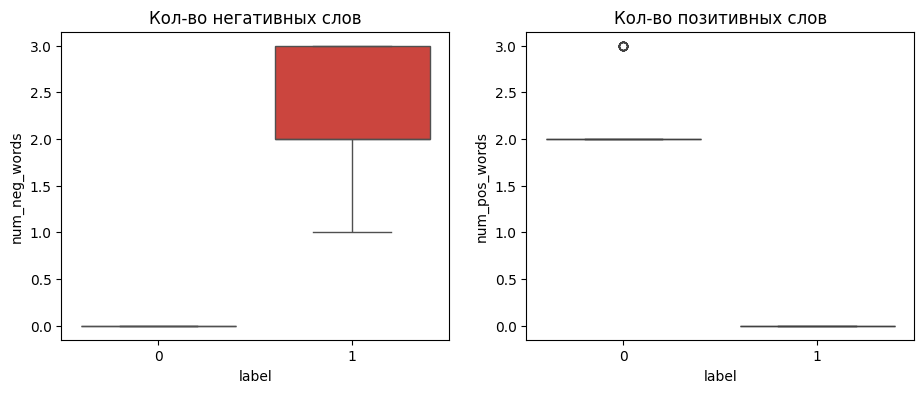

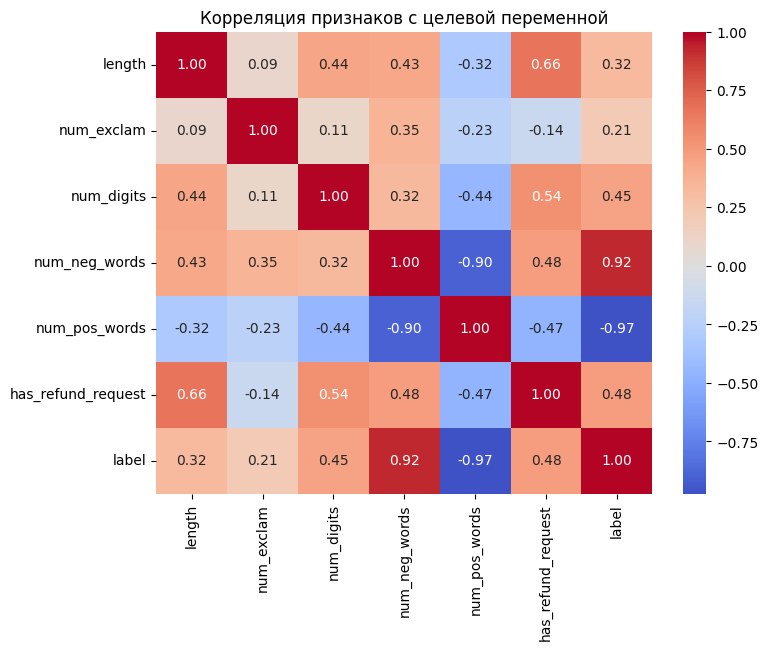

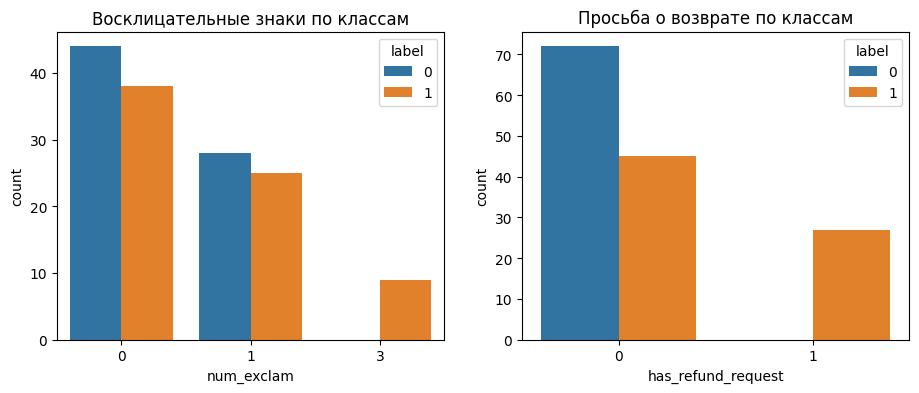

In [2]:
# Баланс классов
plt.figure(figsize=(5, 4))
sns.countplot(x="label", data=df, palette="Set2")
plt.title("Распределение классов (0 - позитив/нейтр., 1 - негатив)")
plt.xlabel("label"); plt.ylabel("Количество")
plt.show()

# Распределение длины отзывов по классам
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="length", hue="label", bins=15,
             kde=True, palette="Set1", alpha=0.6)
plt.title("Длина отзыва в зависимости от класса")
plt.show()

# Негативные / позитивные слова по классам
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x="label", y="num_neg_words", data=df, ax=axes[0], palette="Reds")
axes[0].set_title("Кол-во негативных слов")
sns.boxplot(x="label", y="num_pos_words", data=df, ax=axes[1], palette="Greens")
axes[1].set_title("Кол-во позитивных слов")
plt.show()

# Корреляционная матрица
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=["text"]).corr(), annot=True,
            fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляция признаков с целевой переменной")
plt.show()

# Восклицательные знаки и просьба о возврате
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="num_exclam", hue="label", data=df, ax=axes[0])
axes[0].set_title("Восклицательные знаки по классам")
sns.countplot(x="has_refund_request", hue="label", data=df, ax=axes[1])
axes[1].set_title("Просьба о возврате по классам")
plt.show()

График countplot показывает примерно 45% негатива / 55% позитива - дисбаланс умеренный. Это значит, что при разбиении на train/test обязательно использовать stratify=y, иначе в тестовой выборке пропорция может сместиться и метрики «поплывут». Accuracy как метрика допустима только как вспомогательная.

Гистограмма показывает, что негативные отзывы в среднем длиннее позитивных: клиент, столкнувшийся с проблемой, подробно описывает её и требует возврата. Значит, признак length информативен, но имеет тяжёлый правый хвост - перед подачей в линейные модели стоит логарифмировать (np.log1p), чтобы не давить на масштаб.

Boxplot по num_neg_words и num_pos_words показывает чёткое разделение: у негативных отзывов медиана негативных слов > 0, у позитивных - 0; обратная картина для позитивных слов. Эти признаки - сильнейшие предикторы, но они бинарно-счётные и сильно скошены вправо, поэтому для линейных моделей полезна бинаризация (>0), а для деревьев - оставить как есть.

Наиболее высокие по модулю корреляции с label: num_neg_words (положительная), num_pos_words (отрицательная), has_refund_request (положительная). Признаки num_digits и length коррелируют умеренно. Мультиколлинеарность невысокая, но length и num_neg_words частично связаны - при использовании логистической регрессии стоит проверить VIF.

Негативные отзывы содержат заметно больше ! (клиенты эмоциональны) и почти всегда has_refund_request=1. Эти два признака - дешёвые и интерпретируемые сигналы для бизнеса; в модели их обязательно оставить. При этом has_refund_request почти детерминирован для части негатива - риск утечки (data leakage) минимален, но нужно убедиться, что он не строится на основе целевой переменной.

Проблемы и предобработка:

Стратификация при train/test split (главное!).

Логарифмирование length для линейных моделей.

Масштабирование (StandardScaler) числовых признаков для логистической регрессии / SVM; для деревьев и градиентного бустинга - не обязательно.

Текстовый признак text в текущем виде не используется как фича. Если захочется улучшить качество - можно добавить TF-IDF по тексту и объединить с числовыми признаками (ColumnTransformer).

Кросс-валидация: StratifiedKFold(n_splits=5) - при 68 негативных примерах это даёт ~13-14 объектов класса 1 в каждом фолде, что достаточно для стабильной оценки F1.

Малый объём (150 записей) - риск переобучения. Рекомендуется использовать простые модели (LogisticRegression, DecisionTree с max_depth<=4) и обязательно смотреть разрыв между train и CV метриками.